<a href="https://colab.research.google.com/github/krishnanithesh22-stack/Python-program-on-Chola-influence-in-Southeast-Asia/blob/main/Python_program_on_Chola_influence_in_Southeast_Asia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

print("-" * 60)
print("RAJENDRA CHOLA INFLUENCE IN SOUTHEAST ASIA")
print("-" * 60)
print("Libraries loaded successfully!")

------------------------------------------------------------
RAJENDRA CHOLA INFLUENCE IN SOUTHEAST ASIA
------------------------------------------------------------
Libraries loaded successfully!


In [ ]:
timeline = pd.DataFrame([
    (400, "Kutai Yupa inscriptions (Borneo)", "Sanskrit, Pallava script"),
    (450, "Tarumanagara Ciaruteun inscription (West Java)", "Sanskrit, Pallava script"),
    (611, "Angkor Borei inscription (Cambodia)", "Old Khmer + Sanskrit, Pallava-derived script"),
    (683, "Kedukan Bukit inscription (Srivijaya, Sumatra)", "Old Malay, Pallava-derived script"),
    (732, "Canggal inscription (Central Java)", "Sanskrit, Pallava script"),
    (1010, "Rajaraja I - Chola naval power grows", "Tamil/Sanskrit"),
    (1025, "Rajendra Chola I naval expedition against Srivijaya", "Tamil/Sanskrit"),
    (1030, "Chola-Srivijaya trade revival and diplomacy", "Tamil/Sanskrit"),
    (1088, "Tamil inscription of the merchant guilds at Barus", "Tamil"),
], columns=["Year (CE)", "Event", "Language / Script"])

print("-" * 60)
print("TIMELINE: INDIANIZATION & THE CHOLA EXPEDITION")
print("-" * 60)
print(timeline.to_string(index = False))

------------------------------------------------------------
TIMELINE: INDIANIZATION & THE CHOLA EXPEDITION
------------------------------------------------------------
 Year (CE)                                               Event                            Language / Script
       400                    Kutai Yupa inscriptions (Borneo)                     Sanskrit, Pallava script
       450      Tarumanagara Ciaruteun inscription (West Java)                     Sanskrit, Pallava script
       611                 Angkor Borei inscription (Cambodia) Old Khmer + Sanskrit, Pallava-derived script
       683      Kedukan Bukit inscription (Srivijaya, Sumatra)            Old Malay, Pallava-derived script
       732                  Canggal inscription (Central Java)                     Sanskrit, Pallava script
      1010                Rajaraja I - Chola naval power grows                               Tamil/Sanskrit
      1025 Rajendra Chola I naval expedition against Srivijaya             

In [ ]:
targets = pd.DataFrame([
    ("Gangaikonda Cholapuram", "Chola capital", "Tamil Nadu, India", 11.2086, 79.4496),
    ("Lamuri", "Lamuri-desam", "Aceh, Sumatra", 5.5483, 95.3238),
    ("Nicobar", "Manakkavaram", "Nicobar Islands", 7.0000, 93.8000),
    ("Barus", "Trading port (Tamil guilds)", "North Sumatra", 2.0000, 98.4000),
    ("Palembang", "Sri Vijaya (Srivijaya capital)", "South Sumatra", -2.9761, 104.7754),
    ("Jambi", "Malaiyur / Malayu", "Jambi, Sumatra", -1.6101, 103.6131),
    ("Kedah", "Kadaram / Kataha", "Malaysia", 6.1184, 100.3685),
    ("Pattani", "Ilangasoka / Langkasuka", "Thailand", 6.8692, 101.2500),
    ("Takuapa", "Talaittakkolam", "Thailand", 8.8639, 98.3500),
    ("Nakhon Si Thammarat", "Mevilimbangam / Tambralinga", "Thailand", 8.4304, 99.9631),
], columns=["Place", "Chola-era name", "Modern region", "Latitude", "Longitude"])

print("-" * 60)
print("PLACES LINKED TO RAJENDRA CHOLA'S 1025 CE EXPEDITION")
print("-" * 60)
print(targets.to_string(index = False))

------------------------------------------------------------
PLACES LINKED TO RAJENDRA CHOLA'S 1025 CE EXPEDITION
------------------------------------------------------------
                 Place                 Chola-era name     Modern region  Latitude  Longitude
Gangaikonda Cholapuram                  Chola capital Tamil Nadu, India   11.2086    79.4496
                Lamuri                   Lamuri-desam     Aceh, Sumatra    5.5483    95.3238
               Nicobar                   Manakkavaram   Nicobar Islands    7.0000    93.8000
                 Barus    Trading port (Tamil guilds)     North Sumatra    2.0000    98.4000
             Palembang Sri Vijaya (Srivijaya capital)     South Sumatra   -2.9761   104.7754
                 Jambi              Malaiyur / Malayu    Jambi, Sumatra   -1.6101   103.6131
                 Kedah               Kadaram / Kataha          Malaysia    6.1184   100.3685
               Pattani        Ilangasoka / Langkasuka          Thailand    6.8692

In [ ]:
import plotly.graph_objects as go

home = targets.iloc[0]
others = targets.iloc[1:]

fig = go.Figure()

# Dashed routes from the Chola capital (drawn as curved great-circle paths on the globe)
for _, r in others.iterrows():
    fig.add_trace(go.Scattergeo(
        lon=[home.Longitude, r.Longitude],
        lat=[home.Latitude, r.Latitude],
        mode="lines",
        line=dict(width=1.5, color="gold", dash="dash"),
        hoverinfo="skip",
        showlegend=False,
    ))

# Expedition targets
fig.add_trace(go.Scattergeo(
    lon=others.Longitude,
    lat=others.Latitude,
    mode="markers+text",
    text=others.Place,
    textposition="top right",
    textfont=dict(color="white", size=10),
    marker=dict(size=9, color="crimson", line=dict(width=1, color="white")),
    hovertext=[f"<b>{r.Place}</b><br>Chola-era name: {r['Chola-era name']}<br>{r['Modern region']}"
               for _, r in others.iterrows()],
    hoverinfo="text",
    name="Expedition targets",
))

# Chola capital
fig.add_trace(go.Scattergeo(
    lon=[home.Longitude],
    lat=[home.Latitude],
    mode="markers+text",
    text=[home.Place],
    textposition="top left",
    textfont=dict(color="white", size=11),
    marker=dict(size=16, color="gold", symbol="star", line=dict(width=1, color="black")),
    hovertext=[f"<b>{home.Place}</b><br>{home['Chola-era name']}<br>{home['Modern region']}"],
    hoverinfo="text",
    name="Chola capital",
))

# Blue-green globe, rotatable by dragging
fig.update_geos(
    projection_type="orthographic",
    projection_rotation=dict(lon=95, lat=5, roll=0),   # starting view: centered on Southeast Asia
    showocean=True, oceancolor="#1f6fb2",              # blue ocean
    showland=True, landcolor="#3a9d5d",                # green land
    showcountries=True, countrycolor="#e8f5e9", countrywidth=0.5,
    showcoastlines=True, coastlinecolor="#d9f0e0",
    showlakes=True, lakecolor="#1f6fb2",
    showframe=False,
    bgcolor="rgba(0,0,0,0)",
    lataxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.25)"),
    lonaxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.25)"),
)

fig.update_layout(
    title=dict(text="Rajendra Chola I's Naval Expedition (c. 1025 CE)", x=0.5,
               font=dict(color="white")),
    paper_bgcolor="#0b1d33",
    height=650,
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(font=dict(color="white"), x=0.02, y=0.95),
)

print("-" * 60)
print("INTERACTIVE GLOBE: RAJENDRA CHOLA'S 1025 CE EXPEDITION")
print("-" * 60)
print("Drag to rotate the planet. Scroll to zoom. Hover over markers for details.")

fig.show()

------------------------------------------------------------
INTERACTIVE GLOBE: RAJENDRA CHOLA'S 1025 CE EXPEDITION
------------------------------------------------------------
Drag to rotate the planet. Scroll to zoom. Hover over markers for details.


In [ ]:
import math

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi = p2 - p1
    dlmb = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dlmb/2)**2
    return 2 * R * math.asin(math.sqrt(a))

home = targets.iloc[0]
dist = targets.iloc[1:].copy()
dist["Distance (km)"] = dist.apply(
    lambda r: round(haversine(home.Latitude, home.Longitude, r.Latitude, r.Longitude)), axis=1)
dist = dist.sort_values("Distance (km)")

print("-" * 60)
print("STRAIGHT-LINE DISTANCE FROM GANGAIKONDA CHOLAPURAM")
print("-" * 60)
print(dist[["Place", "Modern region", "Distance (km)"]].to_string(index=False))

------------------------------------------------------------
STRAIGHT-LINE DISTANCE FROM GANGAIKONDA CHOLAPURAM
------------------------------------------------------------
              Place   Modern region  Distance (km)
            Nicobar Nicobar Islands           1643
             Lamuri   Aceh, Sumatra           1855
            Takuapa        Thailand           2085
Nakhon Si Thammarat        Thailand           2268
              Barus   North Sumatra           2328
              Kedah        Malaysia           2367
            Pattani        Thailand           2441
              Jambi  Jambi, Sumatra           3028
          Palembang   South Sumatra           3215


In [ ]:
%pip install -q indic_transliteration

import re
import time
import random
import requests
from indic_transliteration import sanscript

API = "https://en.wiktionary.org/w/api.php"
HEADERS = {"User-Agent": "CholaInfluenceColab/1.0 (educational project)"}
LANGUAGES = ["Indonesian", "Javanese", "Balinese", "Sundanese", "Thai", "Khmer"]
PER_LANG = 8
random.seed(7)

def api(params, retries=5):
    for attempt in range(retries):
        r = requests.get(API, params={**params, "format": "json", "formatversion": 2},
                         headers=HEADERS, timeout=30)
        if r.status_code == 429:                       # rate limited: wait, then retry
            wait = int(r.headers.get("Retry-After", 2 * (attempt + 1)))
            time.sleep(min(wait, 20))
            continue
        r.raise_for_status()
        time.sleep(1)                                  # be polite between calls
        return r.json()
    raise RuntimeError("Wiktionary kept rate-limiting; wait a minute and rerun")

def category_members(lang):
    data = api({"action": "query", "list": "categorymembers",
                "cmtitle": f"Category:{lang} terms derived from Sanskrit",
                "cmlimit": 500, "cmnamespace": 0, "cmtype": "page"})
    return [m["title"] for m in data["query"]["categorymembers"]]

def get_wikitext(titles):
    data = api({"action": "query", "prop": "revisions", "rvprop": "content",
                "rvslots": "main", "titles": "|".join(titles)})
    return {p["title"]: p["revisions"][0]["slots"]["main"]["content"]
            for p in data["query"]["pages"] if "revisions" in p}

def clean(text):
    text = re.sub(r"\{\{(?:l|link|m|mention|w)\|[^|}]*\|([^|}]*)[^}]*\}\}", r"\1", text)
    text = re.sub(r"\{\{(?:gloss|gl|n-g|non-gloss|ng)\|([^|}]*)[^}]*\}\}", r"\1", text)
    text = re.sub(r"\{\{[^{}]*\}\}", "", text)
    text = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", text)
    text = re.sub(r"'{2,}", "", text)
    text = re.sub(r"\([^()]*\)", "", text)             # drop (...) side notes
    text = re.sub(r"[()]", "", text)                   # drop any leftover brackets
    text = re.split(r"[;.]", text)[0]                  # keep first phrase only
    return re.sub(r"\s+", " ", text).strip(" ,;:")

def shorten(text, limit=40):
    if len(text) <= limit:
        return text
    return text[:limit].rsplit(" ", 1)[0] + "…"       # cut at a word boundary

def parse_entry(wikitext, lang):
    sec = re.search(rf"^==\s*{lang}\s*==\s*$(.*?)(?=^==[^=]|\Z)", wikitext, re.S | re.M)
    if not sec:
        return None
    section = sec.group(1)

    t = re.search(r"\{\{(?:bor\+?|lbor|ubor|slbor|der\+?|inh\+?|calque|cal)"
                  r"\|[^|{}]+\|sa\|([^{}]*?)\}\}", section)
    if not t:
        return None
    parts = t.group(1).split("|")
    positional = [p for p in parts if "=" not in p]
    named = dict(p.split("=", 1) for p in parts if "=" in p)
    term = positional[0].strip() if positional else ""
    source = named.get("tr", "").strip()
    if not source:
        if re.search(r"[\u0900-\u097F]", term):
            source = sanscript.transliterate(term, sanscript.DEVANAGARI, sanscript.IAST)
        else:
            source = term
    source = source.split()[0] if source.split() else ""   # first word only
    if not source or source == "-":
        return None

    d = re.search(r"^# (.+)$", section, re.M)
    meaning = clean(d.group(1)) if d else ""
    if not meaning:
        meaning = clean(named.get("t") or named.get("gloss") or
                        (positional[2] if len(positional) > 2 else ""))
    return source, shorten(meaning)

rows, skipped = [], []
for lang in LANGUAGES:
    try:
        members = category_members(lang)
        sample = random.sample(members, min(len(members), 40))
        texts = get_wikitext(sample)
    except Exception as e:
        skipped.append(f"{lang}: {str(e)[:120]}")
        continue
    kept = 0
    for title in sample:
        if kept >= PER_LANG:
            break
        entry = parse_entry(texts.get(title, ""), lang)
        if entry:
            rows.append((lang, title, *entry))
            kept += 1

words = pd.DataFrame(rows, columns=["Language", "Local word", "Sanskrit source", "Meaning"])

print("-" * 60)
print("SANSKRIT LOANWORDS IN SOUTHEAST ASIAN LANGUAGES")
print("-" * 60)
for lang, group in words.groupby("Language", sort=False):
    print(f"\n>>> {lang}")
    print(group.drop(columns="Language").to_string(index=False))

if skipped:
    print("\nCould not load:", *skipped, sep="\n  ")

------------------------------------------------------------
SANSKRIT LOANWORDS IN SOUTHEAST ASIAN LANGUAGES
------------------------------------------------------------

>>> Indonesian
Local word Sanskrit source                              Meaning
   bendoro      bhāṇḍāgāra   master: someone who employs others
     katil          khaṭvā                                  bed
      ardi            adri                             mountain
    birama          virāma                                  bar
      gada            gadā                                 mace
  adiyuswa          āyuṣya                            geriatric
     akson          akṣara axon, a nerve fibre which is a long…
     janda           raṇḍā widow: a woman whose spouse has died

>>> Javanese
Local word Sanskrit source        Meaning
     ꦩꦤ꧀ꦢꦿ          mandra      to travel
 ꦱꦸꦮꦂꦟꦨꦹꦩꦶ    suvarṇabhūmi               
      ꦏꦸꦮꦱ            vaśa       powerful
      ꦠꦺꦴꦪ            toya          water
      ꦥꦿꦏꦱ    

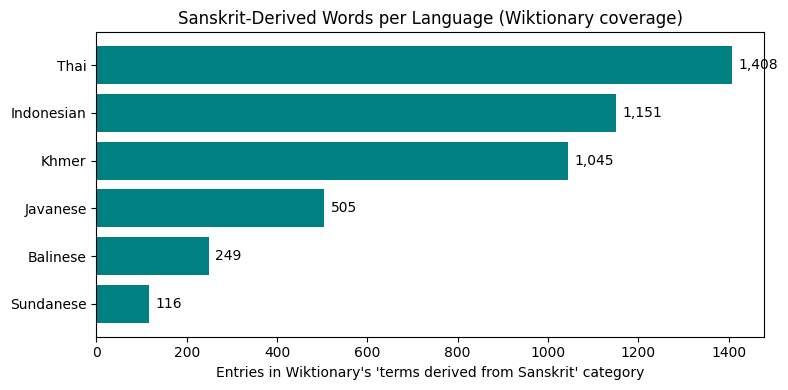

------------------------------------------------------------
SANSKRIT-DERIVED ENTRIES PER LANGUAGE
------------------------------------------------------------
Thai          1408
Indonesian    1151
Khmer         1045
Javanese       505
Balinese       249
Sundanese      116


In [ ]:
real_counts = {}
for lang in LANGUAGES:
    data = api({"action": "query", "prop": "categoryinfo",
                "titles": f"Category:{lang} terms derived from Sanskrit"})
    page = data["query"]["pages"][0]
    real_counts[lang] = page.get("categoryinfo", {}).get("pages", 0)

counts = pd.Series(real_counts).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values, color="teal")
ax.set_xlabel("Entries in Wiktionary's 'terms derived from Sanskrit' category")
ax.set_title("Sanskrit-Derived Words per Language (Wiktionary coverage)")
ax.invert_yaxis()
for i, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, i, f"{v:,}", va="center")
plt.tight_layout()
plt.show()

print("-" * 60)
print("SANSKRIT-DERIVED ENTRIES PER LANGUAGE")
print("-" * 60)
print(counts.to_string())

In [ ]:
print("-" * 60)
print("DESCENT OF SOUTHEAST ASIAN SCRIPTS FROM BRAHMI")
print("-" * 60)
print("""
Brahmi (India, c. 3rd century BCE)
 └── Southern Brahmi
      └── Pallava / Grantha script (South India, c. 4th-7th century CE)
           ├── Old Kawi (Old Javanese) script
           │    ├── Javanese script (Hanacaraka)
           │    ├── Balinese script
           │    ├── Sundanese script (Old Sundanese -> modern Sundanese)
           │    └── Baybayin (Philippines)
           ├── Old Khmer script
           │    ├── Modern Khmer script (Cambodia)
           │    ├── Thai script (via Old Khmer)
           │    └── Lao script (via Thai/Khmer)
           ├── Mon-Burmese scripts
           └── Cham script (Vietnam)
""")

------------------------------------------------------------
DESCENT OF SOUTHEAST ASIAN SCRIPTS FROM BRAHMI
------------------------------------------------------------

Brahmi (India, c. 3rd century BCE)
 └── Southern Brahmi
      └── Pallava / Grantha script (South India, c. 4th-7th century CE)
           ├── Old Kawi (Old Javanese) script
           │    ├── Javanese script (Hanacaraka)
           │    ├── Balinese script
           │    ├── Sundanese script (Old Sundanese -> modern Sundanese)
           │    └── Baybayin (Philippines)
           ├── Old Khmer script
           │    ├── Modern Khmer script (Cambodia)
           │    ├── Thai script (via Old Khmer)
           │    └── Lao script (via Thai/Khmer)
           ├── Mon-Burmese scripts
           └── Cham script (Vietnam)



In [ ]:
import unicodedata

SCRIPTS = ["Brahmi", "Grantha", "Kawi", "Devanagari", "Tamil", "Javanese", "Balinese",
           "Sundanese", "Khmer", "Thai", "Lao", "Myanmar", "Cham"]

# Most scripts name the letter "LETTER KA"; Thai and Lao use other names for the same sound
NAME_PATTERNS = ["{} LETTER KA", "{} CHARACTER KO KAI", "{} LETTER KO"]

rows = []
for script in SCRIPTS:
    for pattern in NAME_PATTERNS:
        try:
            ch = unicodedata.lookup(pattern.format(script.upper()))
        except KeyError:
            continue
        rows.append((script, ch, f"U+{ord(ch):04X}", unicodedata.name(ch),
                     unicodedata.category(ch)))
        break

unicode_df = pd.DataFrame(rows, columns=["Script", "Character", "Code point", "Unicode name", "Category"])

print("-" * 60)
print("THE LETTER 'KA' ACROSS INDIC-DERIVED SCRIPTS (UNICODE)")
print("-" * 60)
print(unicode_df.to_string(index=False))

print()
print("Category 'Lo' = Letter, other (a letter from a non-cased script).")
print("Pallava has no Unicode block of its own, so it is not listed.")
print("Grantha is the closest encoded relative of Pallava.")

------------------------------------------------------------
THE LETTER 'KA' ACROSS INDIC-DERIVED SCRIPTS (UNICODE)
------------------------------------------------------------
    Script Character Code point          Unicode name Category
    Brahmi         𑀓    U+11013      BRAHMI LETTER KA       Lo
   Grantha         𑌕    U+11315     GRANTHA LETTER KA       Lo
      Kawi         𑼒    U+11F12        KAWI LETTER KA       Lo
Devanagari         क     U+0915  DEVANAGARI LETTER KA       Lo
     Tamil         க     U+0B95       TAMIL LETTER KA       Lo
  Javanese         ꦏ     U+A98F    JAVANESE LETTER KA       Lo
  Balinese         ᬓ     U+1B13    BALINESE LETTER KA       Lo
 Sundanese         ᮊ     U+1B8A   SUNDANESE LETTER KA       Lo
     Khmer         ក     U+1780       KHMER LETTER KA       Lo
      Thai         ก     U+0E01 THAI CHARACTER KO KAI       Lo
       Lao         ກ     U+0E81         LAO LETTER KO       Lo
   Myanmar         က     U+1000     MYANMAR LETTER KA       Lo
    

In [ ]:
top_lang = max(real_counts, key=real_counts.get)
far = dist.iloc[-1]
near = dist.iloc[0]

print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Places linked to the 1025 CE expedition  : {len(targets) - 1}")
print(f"Nearest target to the Chola capital      : {near['Place']} ({near['Distance (km)']:,} km)")
print(f"Farthest target from the Chola capital   : {far['Place']} ({far['Distance (km)']:,} km)")
print(f"Languages compared                       : {len(real_counts)}")
print(f"Wiktionary Sanskrit-derived entries      : {sum(real_counts.values()):,}")
print(f"Most documented language                 : {top_lang} ({real_counts[top_lang]:,} entries)")
print(f"Sample words shown in the table          : {len(words)}")
print(f"Scripts compared in Unicode              : {len(unicode_df)}")
print()
print("Key takeaway:")
print("Sanskrit vocabulary and Pallava-derived scripts reached Southeast Asia")
print("centuries BEFORE Rajendra Chola I (r. 1014-1044 CE). His 1025 CE naval")
print("expedition against Srivijaya strengthened existing Tamil trade and")
print("political links, but the deep Sanskrit and script influence on Indonesian,")
print("Thai and Khmer came from earlier Indianization, not from his campaign.")
print()
print("Limits of this analysis:")
print("- Entry counts measure Wiktionary coverage, not total vocabulary size.")
print("- Map routes are illustrative straight lines, not the fleet's sea path.")
print("- Pallava has no Unicode block, so Grantha and Brahmi stand in for it.")

SUMMARY
Places linked to the 1025 CE expedition  : 9
Nearest target to the Chola capital      : Nicobar (1,643 km)
Farthest target from the Chola capital   : Palembang (3,215 km)
Languages compared                       : 6
Wiktionary Sanskrit-derived entries      : 4,474
Most documented language                 : Thai (1,408 entries)
Sample words shown in the table          : 48
Scripts compared in Unicode              : 13

Key takeaway:
Sanskrit vocabulary and Pallava-derived scripts reached Southeast Asia
centuries BEFORE Rajendra Chola I (r. 1014-1044 CE). His 1025 CE naval
expedition against Srivijaya strengthened existing Tamil trade and
political links, but the deep Sanskrit and script influence on Indonesian,
Thai and Khmer came from earlier Indianization, not from his campaign.

Limits of this analysis:
- Entry counts measure Wiktionary coverage, not total vocabulary size.
- Map routes are illustrative straight lines, not the fleet's sea path.
- Pallava has no Unicode block, 